#  Assignment 3


* Use Python as a programming language and finish this assignment
* Work is to be done individually for this assignment
* Students handing in similar work will both receive a grade of 0 and will face disciplinary actions
* Answers generated from AI (e.g., ChatGPT) will receive a grade of 0 and will face academic sanctions




# Part 1-KNN

Data file:

https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/social_network_ads.csv


### Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

1.1 Please load data file (social_network_ads.csv) into dataframe and show the first 10 rows of the dataframe

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/vjavaly/Baruch-CIS-9660/main/data/social_network_ads.csv')
df.head(10)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
5,15728773,Male,27,58000,0
6,15598044,Female,27,84000,0
7,15694829,Female,32,150000,1
8,15600575,Male,25,33000,0
9,15727311,Female,35,65000,0


1.2 Please display a histogram with bins showing the distribution of the variables: Age and EstimatedSalary. Please display the minimum and maximum value for the variable: Age and Estimated Salary. Is the scale for EstimatedSalary is much higher than for Age?

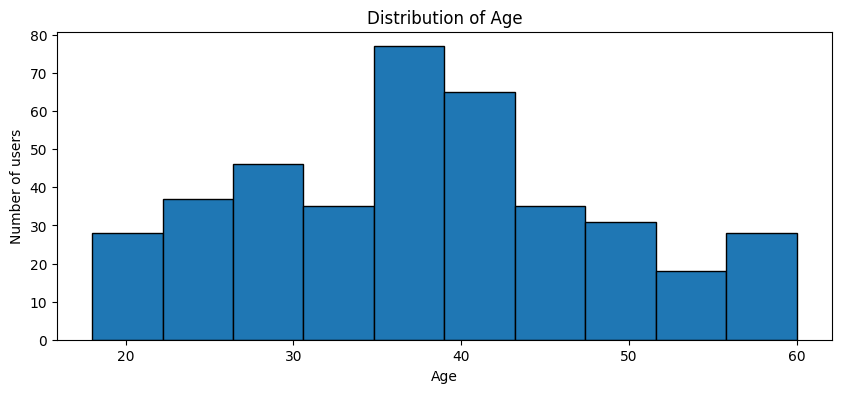

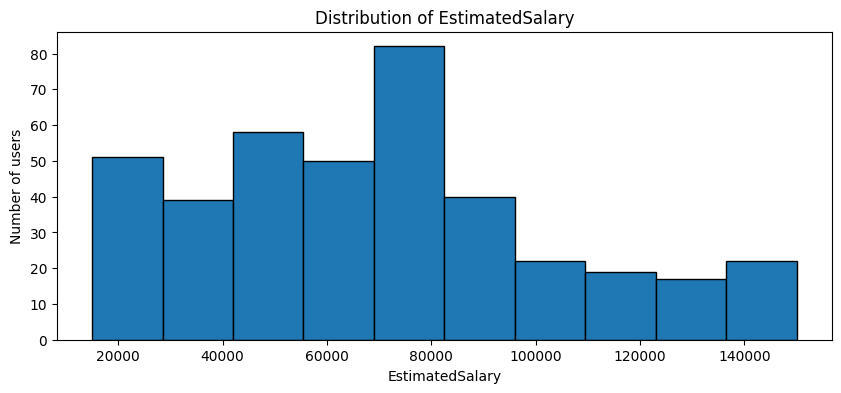

minimum age:  18
maximum age:  60
minimum estimated salary:  15000
maximum estimated salary:  150000


In [3]:
plt.figure(figsize=(10, 4))
# 10 bins
plt.hist(df["Age"], bins=10, edgecolor="black")
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of users")
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(df["EstimatedSalary"], bins=10, edgecolor="black")
plt.title("Distribution of EstimatedSalary")
plt.xlabel("EstimatedSalary")
plt.ylabel("Number of users")
plt.show()

print("minimum age: ", df["Age"].min())
print("maximum age: ", df["Age"].max())
print("minimum estimated salary: ", df["EstimatedSalary"].min())
print("maximum estimated salary: ", df["EstimatedSalary"].max())





The scale for EstimatedSalary is definitely much higher than Age.

1.3 Please dummy encode (one hot encode) column: Gender and create two variables: Gender_Female and Gender_Male (convert boolean values to integers)





In [4]:

df = pd.get_dummies(df, columns=["Gender"], dtype = int)
df.head()

,User ID,Age,EstimatedSalary,Purchased,Gender_Female,Gender_Male
0,15624510,19,19000,0,0,1
1,15810944,35,20000,0,0,1
2,15668575,26,43000,0,1,0
3,15603246,27,57000,0,1,0
4,15804002,19,76000,0,0,1


1.4 Please separate independent variables (All excepted Purchased and drop User_ID) and a dependent variable (e.g. Purchased). In addition, please normalize independent variables Age and EstimatedSalary by uisng MinMaxScaler().Please display the min and max for scaled variables again.


In [5]:
X = df.drop(["Purchased","User ID"], axis = 1)
y = df["Purchased"]
scaler = MinMaxScaler()
X[["Age", "EstimatedSalary"]] = scaler.fit_transform(X[["Age", "EstimatedSalary"]])
print("minimum age: ", X["Age"].min())
print("maximum age: ", X["Age"].max())
print("minimum estimated salary: ", X["EstimatedSalary"].min())
print("maximum estimated salary: ", X["EstimatedSalary"].max())

minimum age:  0.0
maximum age:  0.9999999999999998
minimum estimated salary:  0.0
maximum estimated salary:  1.0


1.5 Please split data into training (75%) and test sets (25%) and train a KNeighborsClassifier (with default hyperparameters).

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)



KNeighborsClassifier()

In [7]:
# Predict using the test set
y_pred = knn.predict(X_test)

In [8]:
knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

1.6 Please evaluate the model performance and print out the accuracy rate.

In [9]:
# Print model accuracy score
print("Accuracy:", accuracy_score(y_test, y_pred)* 100, "%")



Accuracy: 92.0 %


In [10]:
from sklearn.metrics import confusion_matrix
# Print confusion matrix
print(confusion_matrix(y_test, y_pred))

[[58  5]
 [ 3 34]]


In [11]:
from sklearn.metrics import classification_report
# Print classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.92      0.94        63
           1       0.87      0.92      0.89        37

    accuracy                           0.92       100
   macro avg       0.91      0.92      0.92       100
weighted avg       0.92      0.92      0.92       100



Accuracy rate is 92% with a 92% recall and 87% precision for class 1.

1.7 Please Train KNeighborsClassifier (change n_neighbors hyperparameter and at least one other hyperparameter) to improve model accuracy rate


In [49]:
knn = KNeighborsClassifier (n_neighbors= 12, weights = 'distance')
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

In [50]:
# Print model accuracy score
print("Accuracy:", accuracy_score(y_test, y_pred)* 100, "%")

Accuracy: 93.0 %


In [51]:
from sklearn.metrics import classification_report
# Print classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.94      0.94        63
           1       0.89      0.92      0.91        37

    accuracy                           0.93       100
   macro avg       0.92      0.93      0.93       100
weighted avg       0.93      0.93      0.93       100



In [52]:
from sklearn.metrics import confusion_matrix
# Print confusion matrix
print(confusion_matrix(y_test, y_pred))

[[59  4]
 [ 3 34]]


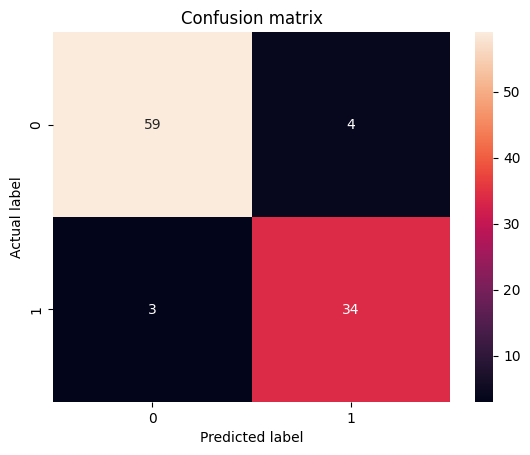

In [57]:
# Create heatmap
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='g')
plt.title('Confusion matrix')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

The accuracy slightly improved to 93% from 92%, precision for class 1 improved from 87% to 89%. We can see from the confusion matrix that false positives decreased from 5 to 4, while true positives remained 34. The new model predicted less false positives without reducing the amount of true positives.

# Part 2- Decision Tree

Data file:
* sklearn : wine

### Import libraries

In [53]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import export_graphviz
import cv2

2.1 Please load wine dataset and show the first 10 rows of the dataframe. In addition, please check for missing values.

In [75]:
wine_data = load_wine()

In [76]:
wine_data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

In [77]:
df_wine = pd.DataFrame(data = wine_data.data,
                       columns = wine_data.feature_names)
df_wine.head(10)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0


2.2 Please separate independent variables and a dependent variable ('lable') , split data into training (80%) and test sets (20%) and train a DecisionTreeClassifier model(random_state=42).

In [78]:
X_wine = df_wine
y_wine = wine_data.target
X_wine_train, X_wine_test, y_wine_train, y_wine_test = train_test_split(X_wine, y_wine, test_size=0.2, random_state=42)


In [79]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_wine_train, y_wine_train)

DecisionTreeClassifier(random_state=42)

2.3 Please evaluate the model (random_state=42) and print out the model accuracy and display the feature importance. How to intepret the feature importance

In [97]:
y_wine_pred = tree.predict(X_wine_test)
print(f"Accuracy = {round((accuracy_score(y_wine_test, y_wine_pred)* 100), 4)}%")

Accuracy = 94.4444%


In [63]:
wine_data.feature_names

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [83]:
tree.feature_importances_

array([0.01899507, 0.        , 0.02094206, 0.        , 0.        ,
       0.        , 0.41105326, 0.        , 0.        , 0.38493424,
       0.        , 0.        , 0.16407537])

In [90]:
pd.DataFrame({
    'Feature': wine_data.feature_names,
    'Importance': tree.feature_importances_
})

,Feature,Importance
0,alcohol,0.018995
1,malic_acid,0.000000
2,ash,0.020942
3,alcalinity_of_ash,0.000000
4,magnesium,0.000000
5,total_phenols,0.000000
6,flavanoids,0.411053
7,nonflavanoid_phenols,0.000000
8,proanthocyanins,0.000000
9,color_intensity,0.384934


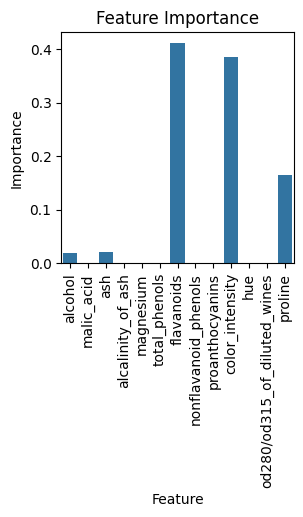

In [89]:
fig = plt.figure(figsize = (3, 3))
sns.barplot(x= wine_data.feature_names, y= tree.feature_importances_)
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.title('Feature Importance')
plt.xticks(rotation = 90)
plt.show()

The Decision Tree achieved 94.44% accuracy. From the feature importance data printed and visualized above we can conclude that flavanoids(41.1%), color intensity(38.5%), and proline(16.4%) combined together account for 96% of the total feature importance of the model. Alcohol(1.8%) and ash(2%) also contributed a little, and the other features weren't used for splitting in the decision tree, and have zero feature importance.

2.4 Please visualize the decision tree and display the directed graph.Could you please intepret the tree results?

In [91]:
import graphviz
from sklearn.tree import export_graphviz

# Visualize decision tree. Create dot file.
dot_data=export_graphviz(tree, out_file =None,
    feature_names = wine_data.feature_names,
    class_names = wine_data.target_names,
    filled = True,
)

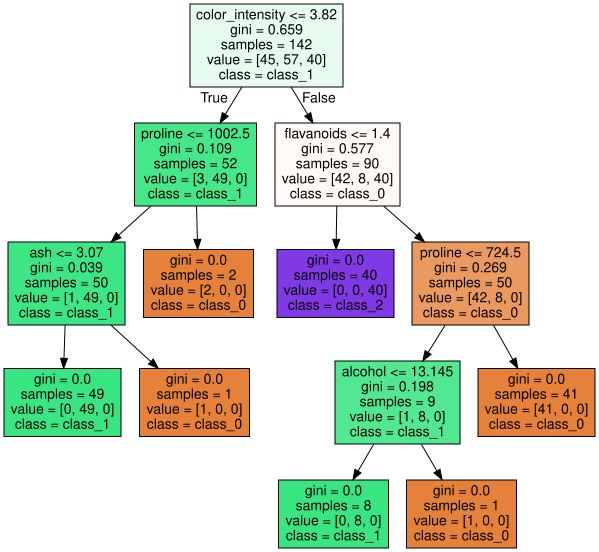

In [94]:
graph=graphviz.Source(dot_data,format="png")
graph

2.5 Please train the model with different hyperparameters to inprove the tree model accuracy and display the feature importance again.

In [95]:
# Analyzing current parameters
tree.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

In [96]:
print("Training accuracy: ", tree.score(X_wine_train, y_wine_train))
print("Testing accuracy: ", tree.score(X_wine_test, y_wine_test))

Training accuracy:  1.0
Testing accuracy:  0.9444444444444444


In [101]:
import numpy as np
# Hyperparamter grid tuning
max_depth = np.arange(2, 14)
min_samples_leaf = np.arange(2, 15, 2)
min_samples_split = [2, 3, 5, 7, 10]

# Create the hyperparameter grid
grid = {'max_depth': max_depth,
        'min_samples_split': min_samples_split,
        'min_samples_leaf': min_samples_leaf
       }

print(grid)

{'max_depth': array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]), 'min_samples_split': [2, 3, 5, 7, 10], 'min_samples_leaf': array([ 2,  4,  6,  8, 10, 12, 14])}


In [102]:
from sklearn.model_selection import GridSearchCV
# Instantiate the grid search model
#  Note: cv=5
gs = GridSearchCV(tree, param_grid=grid,
                  scoring="accuracy", verbose=1,
                  n_jobs=-1, cv=5, return_train_score=True)

In [103]:
# Run grid search
%%time
gs.fit(X_train, y_train)

Fitting 5 folds for each of 420 candidates, totalling 2100 fits
CPU times: user 1.07 s, sys: 53.5 ms, total: 1.13 s
Wall time: 24.5 s


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]),
                         'min_samples_leaf': array([ 2,  4,  6,  8, 10, 12, 14]),
                         'min_samples_split': [2, 3, 5, 7, 10]},
             return_train_score=True, scoring='accuracy', verbose=1)

In [104]:
print("Optimal hyperparameter combination:", gs.best_params_)
print("\nMean cross-validated training accuracy score:", np.round(gs.best_score_,4))

Optimal hyperparameter combination: {'max_depth': np.int64(4), 'min_samples_leaf': np.int64(4), 'min_samples_split': 2}

Mean cross-validated training accuracy score: 0.91


In [106]:
# Re-train the model with best hyperparameters from grid search
gs.best_estimator_.fit(X_wine_train, y_wine_train)

DecisionTreeClassifier(max_depth=np.int64(4), min_samples_leaf=np.int64(4),
                       random_state=42)

In [107]:
y_wine_pred = gs.best_estimator_.predict(X_wine_test)     # Make predictions on test set
grid_search_test_accuracy = np.round(accuracy_score(y_wine_test, y_wine_pred), 4)
print("Test accuracy:", np.round(accuracy_score(y_wine_test, y_wine_pred), 4))

Test accuracy: 0.9444


The accuracy is still 94.44% after hyper-parameter tuning. Will try random search next to see if there could be any improvement.

In [109]:
from sklearn.model_selection import RandomizedSearchCV
# Using the same hyperparameter grid
rs = RandomizedSearchCV(tree, param_distributions=grid,
                        n_iter=100, scoring="accuracy", random_state=42,
                        n_jobs=-1, cv=10, return_train_score=True)

In [110]:
%%time
rs.fit(X_wine_train, y_wine_train)

CPU times: user 582 ms, sys: 29.8 ms, total: 612 ms
Wall time: 13.6 s


RandomizedSearchCV(cv=10, estimator=DecisionTreeClassifier(random_state=42),
                   n_iter=100, n_jobs=-1,
                   param_distributions={'max_depth': array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]),
                                        'min_samples_leaf': array([ 2,  4,  6,  8, 10, 12, 14]),
                                        'min_samples_split': [2, 3, 5, 7, 10]},
                   random_state=42, return_train_score=True,
                   scoring='accuracy')

In [111]:
print("Optimal hyperparameter combination:", rs.best_params_)
print("\tNote: Different combination of hyperparameter values than from grid search")
print("\nMean cross-validated training accuracy score:", np.round(rs.best_score_,4))

Optimal hyperparameter combination: {'min_samples_split': 2, 'min_samples_leaf': np.int64(2), 'max_depth': np.int64(7)}
	Note: Different combination of hyperparameter values than from grid search

Mean cross-validated training accuracy score: 0.8929


In [112]:
# Train with rs.best_params_ from cell above
rs.best_estimator_.fit(X_wine_train, y_wine_train)

DecisionTreeClassifier(max_depth=np.int64(7), min_samples_leaf=np.int64(2),
                       random_state=42)

In [115]:
# Review best Random Search estimator's predictions
y_wine_pred = rs.best_estimator_.predict(X_wine_test)     # Make predictions on test set
random_search_test_accuracy = np.round(accuracy_score(y_wine_test, y_wine_pred), 4)
print("Test accuracy:", np.round(accuracy_score(y_wine_test, y_wine_pred), 4))

Test accuracy: 0.9444


The test accuracy remained 94.44% with a different set of hyperparameters. Even tought the accuracy is the same of all of the models I choose the grid search model, because it has higher cross-validation accuracy 91% vs 89.3% and it is overall simpler with the max_depth of 4 instead of 7 and a minimum of 4 samples per leaf (min_leaf = 4) vs min_leaf = 2 may also help reduce overfitting.

In [116]:
# Feature importance Grid model
pd.DataFrame({
    'Feature': wine_data.feature_names,
    'Importance': gs.best_estimator_.feature_importances_
})

,Feature,Importance
0,alcohol,0.000000
1,malic_acid,0.000000
2,ash,0.000000
3,alcalinity_of_ash,0.000000
4,magnesium,0.000000
5,total_phenols,0.000000
6,flavanoids,0.433903
7,nonflavanoid_phenols,0.000000
8,proanthocyanins,0.000000
9,color_intensity,0.406332


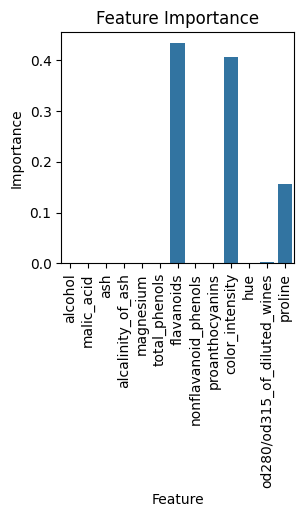

In [117]:
fig = plt.figure(figsize = (3, 3))
sns.barplot(x= wine_data.feature_names, y= gs.best_estimator_.feature_importances_)
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.title('Feature Importance')
plt.xticks(rotation = 90)
plt.show()

After hyperparameter tuning using GridSearchCV, flavonoids(43.39%), color intensity(40.63%), and proline(15.66%) combined together accounted for approximately 99.7% of total feature importance. Alcohol and ash were no loner used by the new model for splitting, and with these changes the test accuracy still remained 94.44%.

2.6 Please visualize the new tree model output and display the directed graph. Please try to explain the tree results

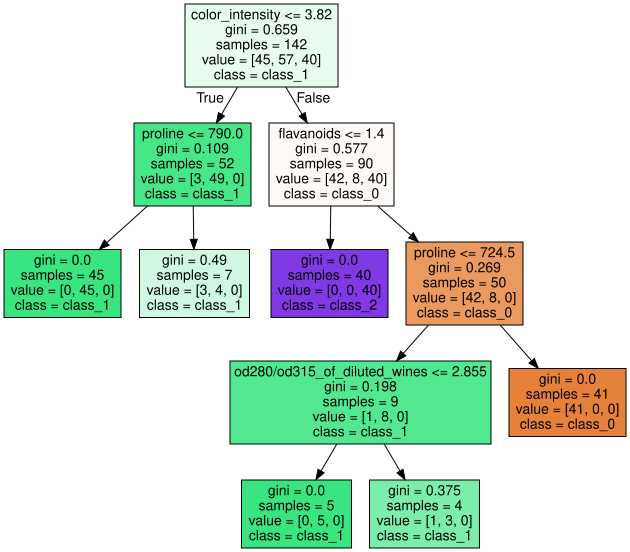

In [118]:
import graphviz
from sklearn.tree import export_graphviz

# Visualize decision tree. Create dot file.
dot_data=export_graphviz(gs.best_estimator_, out_file =None,
    feature_names = wine_data.feature_names,
    class_names = wine_data.target_names,
    filled = True,
)

graph = graphviz.Source(dot_data, format = "png")
graph

In [119]:
print("Tuned training accuracy:", gs.best_estimator_.score(X_wine_train, y_wine_train))

Tuned training accuracy: 0.971830985915493


After hyperparameter tuning with GridSearchCV, the new decision tree achieved 97.18% training accuracy and 94.44% testing accuracy, compared to 100% and 94.44% for the original model. This means that the new model narrowed the gap between training and testing accuracy. There are also some impure terminal leaves (Gini > 0) because the minimum samples per leaf parameter restricts further splitting. Although tuning did not improve testing accuracy, it reduced the model's possibility to overfit the training data.